# E- handelsanalyysis

## Project syfte

Analysera försäljningsdata for att idetentifera använbara mönster och ge ledgning beslut innan nästa kampanjperiod.

## Frågeställningar

1. Vilka produkt kategorier driver mest intäkt?
2. Vilka städer står för störst intäkt?
3. Hur ser ut Försaljningen över tid?
4. Hur ser en typisk order ut? – AOV (Average Order Value) och spridning.
5. Topp-listor – topp-3 kategorier efter intäkt.
6. Finns det avvikelser eller något oväntat mönster i data?



In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import sys

In [10]:
import os

os.chdir("..")

print(os.getcwd())
print(os.listdir())

c:\Users\suhaa\OneDrive\Desktop\Group_project
['.git', '.gitignore', 'data', 'notebooks', 'README.md', 'requirements.txt', 'src']


In [13]:


from src.io_utils import load_data
df = load_data()


In [14]:
df.head()

,order_id,date,city,category,price,units,revenue
0,100000,2024-04-19,Stockholm,Sports,530.95,4,2123.80
1,100001,2024-05-06,Malmö,Sports,653.28,3,1959.84
2,100002,2024-03-07,Uppsala,Clothing,177.98,4,711.92
3,100003,2024-04-08,Göteborg,Home,348.57,3,1045.71
4,100004,2024-01-18,Uppsala,Electronics,777.07,3,2331.21


In [15]:
print("Ecommerce data Information")
df.info()


Ecommerce data Information
<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   order_id  2500 non-null   int64  
 1   date      2500 non-null   str    
 2   city      2500 non-null   str    
 3   category  2500 non-null   str    
 4   price     2500 non-null   float64
 5   units     2500 non-null   int64  
 6   revenue   2500 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 136.8 KB


In [18]:
print("Statistics")

print(df.describe())
print()

Statistics
           order_id        price        units      revenue
count    2500.00000  2500.000000  2500.000000  2500.000000
mean   101249.50000   476.213212     2.985200  1401.106892
std       721.83216   312.968413     1.429755  1166.944967
min    100000.00000    50.000000     1.000000    50.000000
25%    100624.75000   254.960000     2.000000   577.960000
50%    101249.50000   413.045000     3.000000  1088.690000
75%    101874.25000   624.427500     4.000000  1884.750000
max    102499.00000  2092.530000     9.000000  9192.600000



In [19]:
print(df.isna().sum())
print()

print("Duplicates:" ,df.duplicated().sum())
print()

order_id    0
date        0
city        0
category    0
price       0
units       0
revenue     0
dtype: int64

Duplicates: 0



In [20]:

df["date"] = pd.to_datetime(df["date"], errors="coerce")

print("Date:" "From", df["date"] . min() , "to" ,df["date"].max())

Date:From 2024-01-01 00:00:00 to 2024-06-30 00:00:00


In [22]:
print("Cities:" ,list(df["city"].unique()))
print()

print("Produkt Categories:" ,list(df["category"].unique()))
print()

Cities: ['Stockholm', 'Malmö', 'Uppsala', 'Göteborg', 'Västerås']

Produkt Categories: ['Sports', 'Clothing', 'Home', 'Electronics', 'Toys', 'Beauty']



## Beräkna total Intäkten

In [29]:
#Total intäkt och Antal enheter

total_intäkt = df["revenue"].sum()
print(f"Total intäkt: {total_intäkt:,.2f} kr")
print()

antal_enheter = df["units"].sum()
print(f"Total antal enheter: {antal_enheter}")


Total intäkt: 3,502,767.23 kr

Total antal enheter: 7463


In [35]:
import importlib
import src.metrics as metrics

## Intäkt per stad

In [37]:
#Intäkt Per Stad

#Tabell

stads_intäkt = metrics.intäkt_per_stad(df)

stads_intäkt_tabell = stads_intäkt.reset_index()
stads_intäkt_tabell.columns = ["Stad" , "Total intäkt"]

display(stads_intäkt_tabell)



,Stad,Total intäkt
0,Stockholm,1227201.94
1,Göteborg,859019.65
2,Malmö,567926.32
3,Uppsala,551478.42
4,Västerås,297140.90


In [42]:
högst_intäkt_stad = stads_intäkt.idxmax()
hogsta_stads_intakt = stads_intäkt.max()

print(f"Stad med högst intäkt: {högst_intäkt_stad}")
print(f"Högsta stads intäkten: {hogsta_stads_intakt:,.2f} kr")

Stad med högst intäkt: Stockholm
Högsta stads intäkten: 1,227,201.94 kr


In [ ]:
# kategori intäkt 

In [ ]:
# Top tre kategori

In [ ]:
# månads intäkt

In [ ]:
#aov

In [55]:
#ordervalue distribution


import importlib
import src.metrics as metrics

importlib.reload(metrics)

order_values = metrics.ordervarden(df)

print("Antal unika orderr:", order_values.size)
print(f"Lägsta ordervärde: {order_values.min():,.2f} kr")
print(f"Median för ordervärde: {order_values.median():,.2f} kr")
print(f"Högsta ordervärde: {order_values.max():,.2f} kr")

Antal unika orderr: 2500
Lägsta ordervärde: 50.00 kr
Median för ordervärde: 1,088.69 kr
Högsta ordervärde: 9,192.60 kr


In [57]:
nyckeltal_tabell = pd.DataFrame({
    "Nyckeltal": [
        "Total intäkt",
        "Totalt antal sålda enheter",
        "Antal unika ordrar",
        "Stad med högst intäkt",
    ],
    "Resultat": [
        f"{total_intäkt:,.2f} kr",
        f"{antal_enheter:,}",
        f"{order_values.size:,}",
        str(stads_intäkt.idxmax()),
        
    ]
})

display(nyckeltal_tabell)


,Nyckeltal,Resultat
0,Total intäkt,"3,502,767.23 kr"
1,Totalt antal sålda enheter,"7,463"
2,Antal unika ordrar,"2,500"
3,Stad med högst intäkt,Stockholm


# Visualization

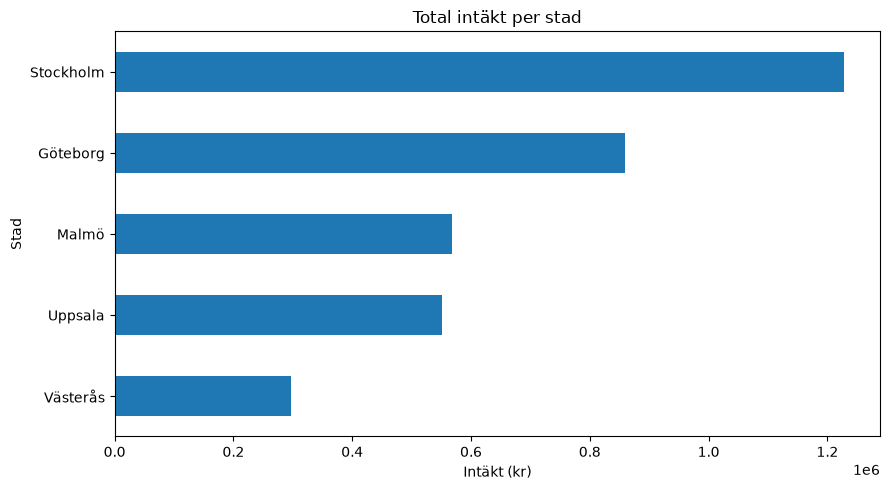

In [52]:
#plot intäkt per stad

def plot_intakt_per_stad(stads_intäkt):
    stads_intäkt.sort_values().plot(
        kind="barh",
        figsize=(9, 5)
    )

    plt.title("Total intäkt per stad")
    plt.xlabel("Intäkt (kr)")
    plt.ylabel("Stad")
    plt.tight_layout()
    plt.show()
plot_intakt_per_stad(stads_intäkt)

In [ ]:
#plot kategory

In [ ]:
#plot topp tre kategori

In [ ]:
#plot försäjlning over tid

In [ ]:
#Aov

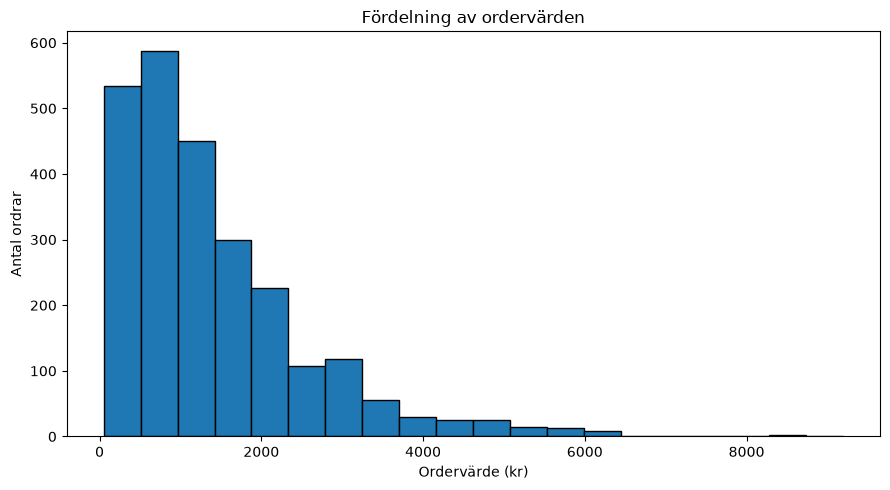

In [58]:
#order value distributin

def plot_ordervarden(order_values):

    plt.figure(figsize=(9, 5))

    plt.hist(order_values, bins=20, edgecolor="black")

    plt.title("Fördelning av ordervärden")
    plt.xlabel("Ordervärde (kr)")
    plt.ylabel("Antal ordrar")
    plt.tight_layout()
    plt.show()

plot_ordervarden(order_values)

##Analysera  avvikelser och något oväntat mönster
